In [ ]:

# Import libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files
from IPython.display import display

print("Libraries imported successfully.")


Libraries imported successfully.


In [ ]:

# Upload FAOSTAT CSV

uploaded = files.upload()

if not uploaded:
    raise ValueError("Please upload your FAOSTAT CSV file.")

filename = next(iter(uploaded))
print("Uploaded file:", filename)

df = pd.read_csv(filename, encoding="utf-8-sig")

print("File loaded successfully.")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])


Saving FAOSTAT_data_en_10-28-2026 (3).csv to FAOSTAT_data_en_10-28-2026 (3).csv
Uploaded file: FAOSTAT_data_en_10-28-2026 (3).csv
File loaded successfully.
Rows: 519
Columns: 15


In [ ]:

#  Inspect the dataset

print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

print("\nAvailable years:")
print(sorted(df["Year"].dropna().unique().tolist()))

print("\nProduction elements:")
print(df["Element"].value_counts(dropna=False))


Dataset shape: (519, 15)

Column names:
['Domain Code', 'Domain', 'Area Code (M49)', 'Area', 'Element Code', 'Element', 'Item Code (CPC)', 'Item', 'Year Code', 'Year', 'Unit', 'Value', 'Flag', 'Flag Description', 'Note']

First 5 rows:


,Domain Code,Domain,Area Code (M49),Area,Element Code,Element,Item Code (CPC),Item,Year Code,Year,Unit,Value,Flag,Flag Description,Note
0,QCL,Crops and livestock products,50,Bangladesh,5510,Production,1654.0,"Anise, badian, coriander, cumin, caraway, fenn...",2017,2017,t,NaN,M,Missing value; data cannot exist,NaN
1,QCL,Crops and livestock products,50,Bangladesh,5510,Production,1654.0,"Anise, badian, coriander, cumin, caraway, fenn...",2018,2018,t,NaN,M,Missing value; data cannot exist,NaN
2,QCL,Crops and livestock products,50,Bangladesh,5510,Production,1654.0,"Anise, badian, coriander, cumin, caraway, fenn...",2019,2019,t,NaN,M,Missing value; data cannot exist,NaN
3,QCL,Crops and livestock products,50,Bangladesh,5510,Production,1654.0,"Anise, badian, coriander, cumin, caraway, fenn...",2020,2020,t,NaN,M,Missing value; data cannot exist,NaN
4,QCL,Crops and livestock products,50,Bangladesh,5510,Production,1654.0,"Anise, badian, coriander, cumin, caraway, fenn...",2021,2021,t,NaN,M,Missing value; data cannot exist,NaN



Available years:
[2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024]

Production elements:
Element
Production    519
Name: count, dtype: int64


In [ ]:

#  Clean and filter crop production data

required_columns = ["Area", "Element", "Item", "Year", "Unit", "Value"]
missing_columns = [c for c in required_columns if c not in df.columns]

if missing_columns:
    raise ValueError(f"Missing columns: {missing_columns}")

data = df.copy()

data["Area"] = data["Area"].astype("string").str.strip()
data["Element"] = data["Element"].astype("string").str.strip()
data["Item"] = data["Item"].astype("string").str.strip()
data["Unit"] = data["Unit"].astype("string").str.strip()

data["Year"] = pd.to_numeric(data["Year"], errors="coerce")
data["Value"] = pd.to_numeric(data["Value"], errors="coerce")

# Keep Bangladesh crop production rows only
data = data[
    (data["Area"].str.casefold() == "bangladesh") &
    (data["Element"].str.casefold() == "production")
].copy()

# Use the exact item names found in your CSV
target_items = ["Rice", "Maize (corn)", "Sugar cane"]

crops = data[data["Item"].isin(target_items)].copy()
crops = crops.dropna(subset=["Year", "Value"])
crops["Year"] = crops["Year"].astype(int)

# Ensure each crop-year has only one record
duplicates = crops.duplicated(subset=["Item", "Year"], keep=False)

print("Selected crop records:", len(crops))
print("Selected crops:", crops["Item"].unique().tolist())
print("Years:", sorted(crops["Year"].unique().tolist()))

if crops.empty:
    print("No matching records found. Check the item names in Cell 3.")
else:
    print("\nData quality check:")
    print("Duplicate crop-year rows:", int(duplicates.sum()))
    print("Units:", crops["Unit"].unique().tolist())
    display(crops.sort_values(["Item", "Year"]))


Selected crop records: 24
Selected crops: ['Maize (corn)', 'Rice', 'Sugar cane']
Years: [2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024]

Data quality check:
Duplicate crop-year rows: 0
Units: ['t']


,Domain Code,Domain,Area Code (M49),Area,Element Code,Element,Item Code (CPC),Item,Year Code,Year,Unit,Value,Flag,Flag Description,Note
200,QCL,Crops and livestock products,50,Bangladesh,5510,Production,112.0,Maize (corn),2017,2017,t,3025392.00,A,Official value,NaN
201,QCL,Crops and livestock products,50,Bangladesh,5510,Production,112.0,Maize (corn),2018,2018,t,3288102.00,A,Official value,NaN
202,QCL,Crops and livestock products,50,Bangladesh,5510,Production,112.0,Maize (corn),2019,2019,t,3569321.00,A,Official value,NaN
203,QCL,Crops and livestock products,50,Bangladesh,5510,Production,112.0,Maize (corn),2020,2020,t,4015306.00,A,Official value,NaN
204,QCL,Crops and livestock products,50,Bangladesh,5510,Production,112.0,Maize (corn),2021,2021,t,4116438.00,A,Official value,NaN
205,QCL,Crops and livestock products,50,Bangladesh,5510,Production,112.0,Maize (corn),2022,2022,t,4261845.00,A,Official value,NaN
206,QCL,Crops and livestock products,50,Bangladesh,5510,Production,112.0,Maize (corn),2023,2023,t,4592507.00,A,Official value,NaN
207,QCL,Crops and livestock products,50,Bangladesh,5510,Production,112.0,Maize (corn),2024,2024,t,4592508.00,A,Official value,NaN
408,QCL,Crops and livestock products,50,Bangladesh,5510,Production,113.0,Rice,2017,2017,t,52079606.96,A,Official value,NaN
409,QCL,Crops and livestock products,50,Bangladesh,5510,Production,113.0,Rice,2018,2018,t,54614714.97,A,Official value,NaN


In [ ]:

#  Create a year-by-year production table

if crops.empty:
    raise ValueError("No crop data available. Run Cell 4 and check the item names.")

if crops.duplicated(subset=["Item", "Year"]).any():
    raise ValueError("Duplicate crop-year records found. Inspect Cell 4 before proceeding.")

units_per_crop = crops.groupby("Item")["Unit"].nunique()
if (units_per_crop > 1).any():
    raise ValueError("A crop has multiple units. Standardize units before analysis.")

production_table = crops.pivot(
    index="Year",
    columns="Item",
    values="Value"
).sort_index()

production_table = production_table.rename(columns={
    "Rice": "Rice_tonnes",
    "Maize (corn)": "Maize_tonnes",
    "Sugar cane": "Sugar_cane_tonnes"
})

print("Annual crop production (tonnes):")
display(production_table.round(2))


Annual crop production (tonnes):


Item,Maize_tonnes,Rice_tonnes,Sugar_cane_tonnes
Year,,,
2017,3025392.0,52079606.96,3862775.0
2018,3288102.0,54614714.97,3638731.0
2019,3569321.0,54784186.92,3141923.0
2020,4015306.0,56056815.18,3682951.0
2021,4116438.0,56772472.25,3332546.0
2022,4261845.0,57776021.60,3087428.0
2023,4592507.0,60601180.62,2982546.0
2024,4592508.0,60570453.05,2933694.0


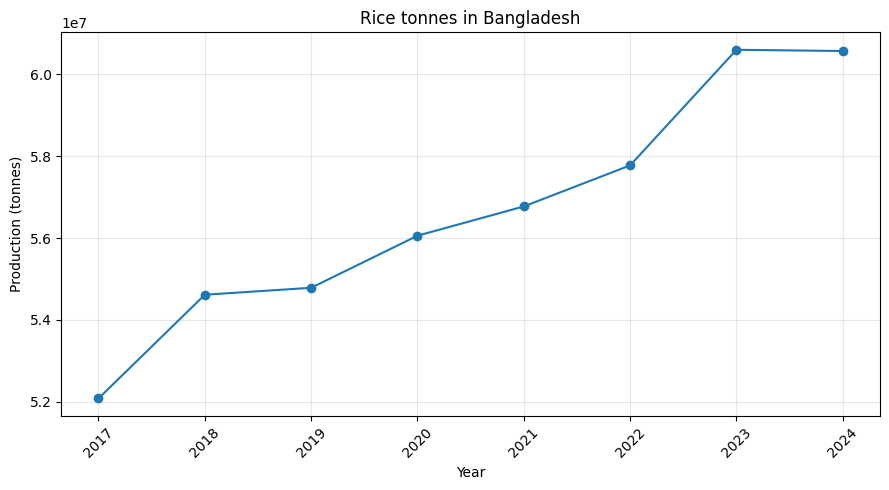

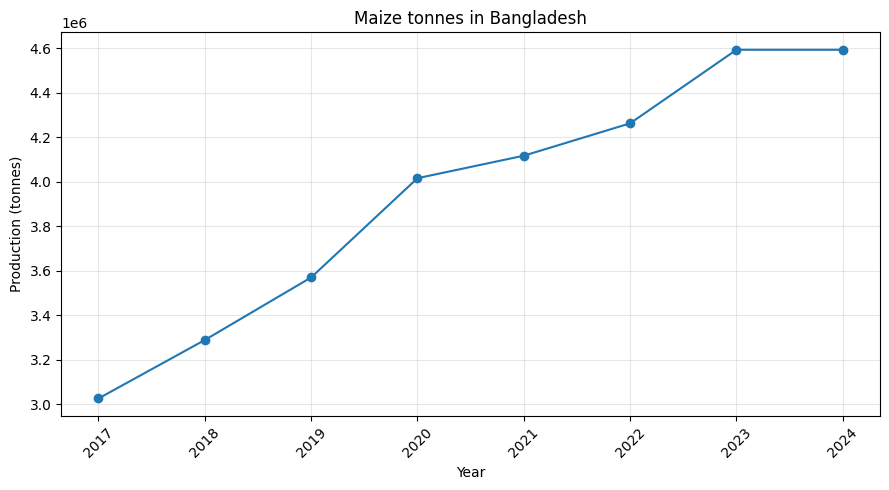

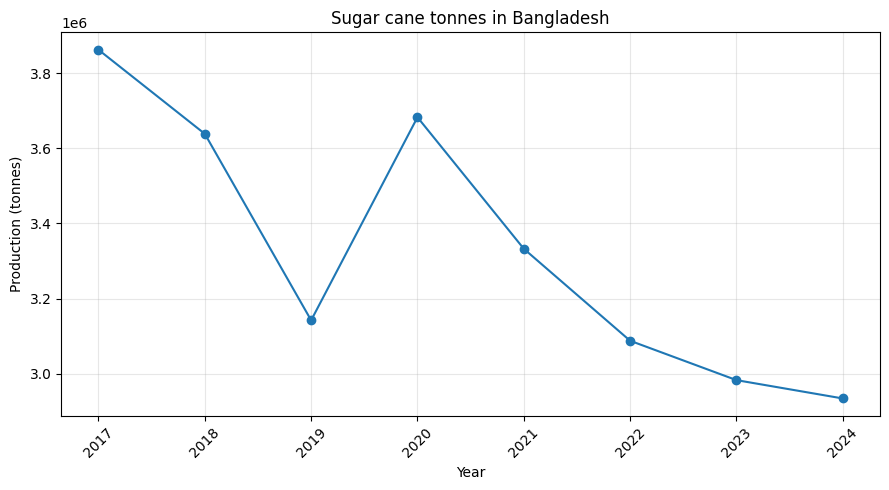

In [ ]:

# Plot annual production trends

plot_columns = [
    "Rice_tonnes",
    "Maize_tonnes",
    "Sugar_cane_tonnes"
]

for column in plot_columns:
    if column not in production_table.columns:
        print("Skipping missing column:", column)
        continue

    series = production_table[column].dropna()

    plt.figure(figsize=(9, 5))
    plt.plot(series.index, series.values, marker="o")
    plt.title(column.replace("_", " ") + " in Bangladesh")
    plt.xlabel("Year")
    plt.ylabel("Production (tonnes)")
    plt.xticks(series.index, rotation=45)
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()


In [ ]:

#  Calculate observed production changes

results = []

for crop_name in production_table.columns:
    series = production_table[crop_name].dropna().sort_index()

    if len(series) < 2:
        continue

    first_year = int(series.index[0])
    last_year = int(series.index[-1])
    first_value = float(series.iloc[0])
    last_value = float(series.iloc[-1])

    change = last_value - first_value
    percent_change = (
        (change / first_value) * 100
        if first_value != 0 else np.nan
    )

    results.append({
        "Crop": crop_name,
        "First year": first_year,
        "First production (tonnes)": first_value,
        "Last year": last_year,
        "Last production (tonnes)": last_value,
        "Change (tonnes)": change,
        "Change (%)": percent_change
    })

change_table = pd.DataFrame(results)

display(change_table.round(2))


,Crop,First year,First production (tonnes),Last year,Last production (tonnes),Change (tonnes),Change (%)
0,Maize_tonnes,2017,3025392.00,2024,4592508.00,1567116.00,51.80
1,Rice_tonnes,2017,52079606.96,2024,60570453.05,8490846.09,16.30
2,Sugar_cane_tonnes,2017,3862775.00,2024,2933694.00,-929081.00,-24.05


In [ ]:

#  Save research outputs

crops.to_csv("bangladesh_crop_production_clean.csv", index=False)
production_table.to_csv("annual_crop_production_table.csv")
change_table.to_csv("crop_production_change_summary.csv", index=False)

print("Research files created:")
print("1. bangladesh_crop_production_clean.csv")
print("2. annual_crop_production_table.csv")
print("3. crop_production_change_summary.csv")

files.download("bangladesh_crop_production_clean.csv")
files.download("annual_crop_production_table.csv")
files.download("crop_production_change_summary.csv")


Research files created:
1. bangladesh_crop_production_clean.csv
2. annual_crop_production_table.csv
3. crop_production_change_summary.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

# Create a scientific parameter template

parameters = pd.DataFrame({
    "Residue": [
        "Rice straw",
        "Rice husk",
        "Maize stover",
        "Sugarcane bagasse"
    ],
    "Parent crop": [
        "Rice",
        "Rice",
        "Maize (corn)",
        "Sugar cane"
    ],
    "Residue_to_product_ratio": [np.nan] * 4,
    "Recoverable_fraction": [np.nan] * 4,
    "Moisture_fraction_wet_basis": [np.nan] * 4,
    "LHV_MJ_per_kg_dry": [np.nan] * 4,
    "Reference_title": [""] * 4,
    "DOI_or_source_URL": [""] * 4,
    "Notes": [""] * 4
})

parameters.to_csv("biomass_parameter_template.csv", index=False)

display(parameters)
files.download("biomass_parameter_template.csv")


,Residue,Parent crop,Residue_to_product_ratio,Recoverable_fraction,Moisture_fraction_wet_basis,LHV_MJ_per_kg_dry,Reference_title,DOI_or_source_URL,Notes
0,Rice straw,Rice,NaN,NaN,NaN,NaN,,,
1,Rice husk,Rice,NaN,NaN,NaN,NaN,,,
2,Maize stover,Maize (corn),NaN,NaN,NaN,NaN,,,
3,Sugarcane bagasse,Sugar cane,NaN,NaN,NaN,NaN,,,


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

#  Format the research results clearly

summary = change_table.copy()

summary = summary.rename(columns={
    "Crop": "Crop",
    "First year": "First year",
    "First production (tonnes)": "Production in first year (tonnes)",
    "Last year": "Last year",
    "Last production (tonnes)": "Production in last year (tonnes)",
    "Change (tonnes)": "Absolute change (tonnes)",
    "Change (%)": "Percentage change (%)"
})

summary["Absolute change (tonnes)"] = (
    summary["Absolute change (tonnes)"].round(2)
)
summary["Percentage change (%)"] = (
    summary["Percentage change (%)"].round(2)
)

display(summary.reset_index(drop=True))

summary.to_csv("crop_production_change_summary_formatted.csv", index=False)
print("Formatted results table saved.")


,Crop,First year,Production in first year (tonnes),Last year,Production in last year (tonnes),Absolute change (tonnes),Percentage change (%)
0,Maize_tonnes,2017,3025392.00,2024,4592508.00,1567116.00,51.80
1,Rice_tonnes,2017,52079606.96,2024,60570453.05,8490846.09,16.30
2,Sugar_cane_tonnes,2017,3862775.00,2024,2933694.00,-929081.00,-24.05


Formatted results table saved.


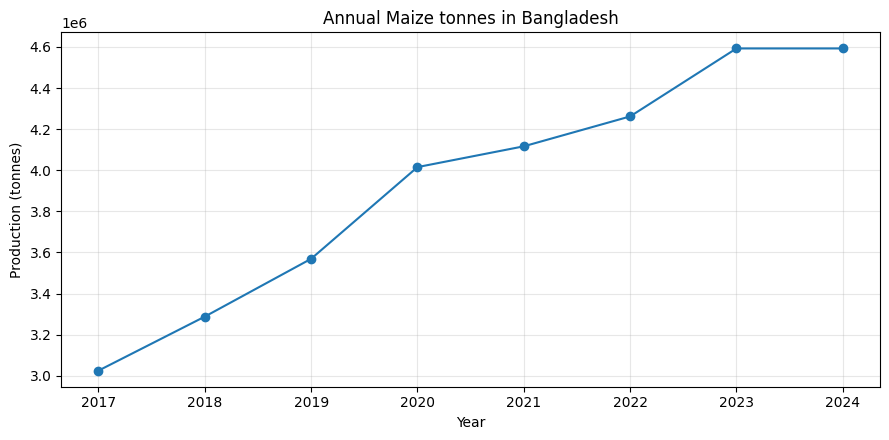

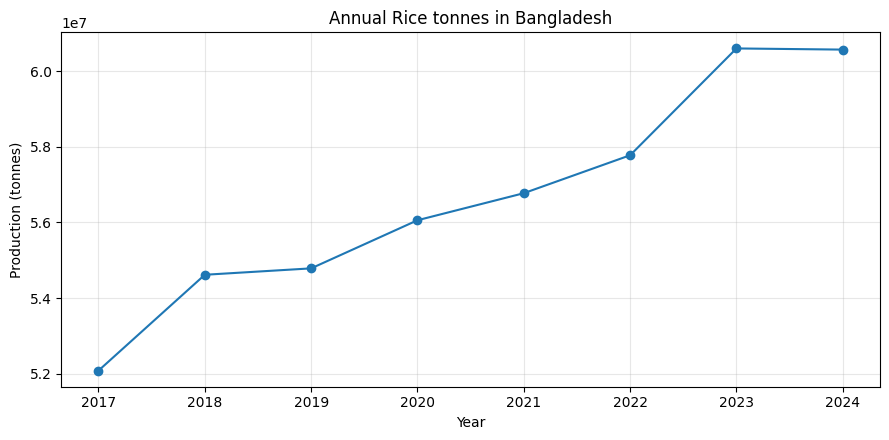

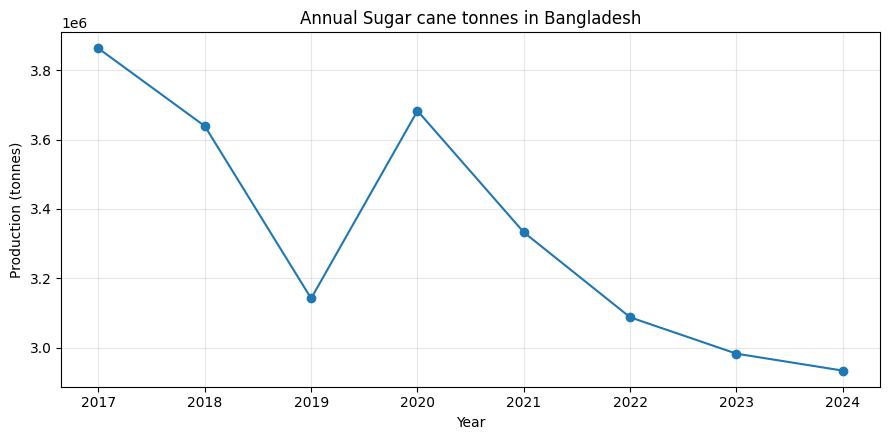

In [ ]:

#  Display all crop production trends

for crop in production_table.columns:
    series = production_table[crop].dropna().sort_index()

    plt.figure(figsize=(9, 4.5))
    plt.plot(series.index, series.values, marker="o")
    plt.title(f"Annual {crop.replace('_', ' ')} in Bangladesh")
    plt.xlabel("Year")
    plt.ylabel("Production (tonnes)")
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()


In [ ]:

# ============================================================
#  Literature-based gross residue estimates
# Country: Bangladesh | Years: 2017-2024
# Important: These are scenario estimates, not measured biomass.
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
from google.colab import files

# Literature-based RPR scenarios (kg residue / kg crop product)
# Low / central / high values are taken from published ranges.
# They are NOT confirmed Bangladesh-specific measurements.

parameters = pd.DataFrame([
    {
        "Residue": "Rice straw",
        "Crop_column": "Rice_tonnes",
        "RPR_low": 0.8,
        "RPR_central": 1.5,
        "RPR_high": 2.5,
        "Reference": "Yevich & Logan (2003), Table 3",
        "DOI": "https://doi.org/10.1029/2002GB001952",
        "Caution": "Rice product basis must be checked"
    },
    {
        "Residue": "Rice husk",
        "Crop_column": "Rice_tonnes",
        "RPR_low": 0.17,
        "RPR_central": 0.20,
        "RPR_high": 0.22,
        "Reference": "Yevich & Logan (2003), Table 3; FAO conversion table",
        "DOI": "https://doi.org/10.1029/2002GB001952",
        "Caution": "Husk ratio depends on paddy/grain basis"
    },
    {
        "Residue": "Maize stover",
        "Crop_column": "Maize_tonnes",
        "RPR_low": 0.9,
        "RPR_central": 2.0,
        "RPR_high": 4.0,
        "Reference": "Yevich & Logan (2003), Table 3",
        "DOI": "https://doi.org/10.1029/2002GB001952",
        "Caution": "Broad literature range; local validation needed"
    },
    {
        "Residue": "Sugarcane bagasse",
        "Crop_column": "Sugar_cane_tonnes",
        "RPR_low": 0.05,
        "RPR_central": 0.15,
        "RPR_high": 0.20,
        "Reference": "Yevich & Logan (2003), Table 3; FAO conversion table",
        "DOI": "https://doi.org/10.1029/2002GB001952",
        "Caution": "Best based on cane crushed at sugar mills"
    }
])

# Check that the previous production analysis exists
if "production_table" not in globals():
    raise NameError("Run Cells 1-6 first to create production_table.")

# Check expected columns
needed = sorted(parameters["Crop_column"].unique())
missing = [c for c in needed if c not in production_table.columns]

if missing:
    raise ValueError(
        f"Missing crop columns: {missing}. "
        "Check the column names in production_table."
    )

# Inspect the rice item before calculating
print("Rice item used in your FAOSTAT file:")
print(crops.loc[
    crops["Item"].str.contains("rice", case=False, na=False),
    ["Item", "Unit"]
].drop_duplicates().to_string(index=False))

print(
    "\nIMPORTANT: Verify whether the FAOSTAT rice series represents "
    "paddy rice or another rice product before interpreting rice residues."
)

# Calculate scenario estimates
records = []

for year, row in production_table.sort_index().iterrows():
    for _, p in parameters.iterrows():
        crop_value = row[p["Crop_column"]]

        if pd.isna(crop_value):
            continue

        records.append({
            "Year": int(year),
            "Residue": p["Residue"],
            "Crop_production_tonnes": float(crop_value),
            "RPR_low": p["RPR_low"],
            "RPR_central": p["RPR_central"],
            "RPR_high": p["RPR_high"],
            "Gross_residue_low_tonnes": crop_value * p["RPR_low"],
            "Gross_residue_central_tonnes": crop_value * p["RPR_central"],
            "Gross_residue_high_tonnes": crop_value * p["RPR_high"],
            "Reference": p["Reference"],
            "DOI": p["DOI"],
            "Caution": p["Caution"]
        })

biomass = pd.DataFrame(records)

print("\nGross residue estimates — tonnes/year")
display(
    biomass[[
        "Year", "Residue",
        "Gross_residue_low_tonnes",
        "Gross_residue_central_tonnes",
        "Gross_residue_high_tonnes"
    ]].round(0)
)

biomass.to_csv("gross_biomass_scenario_estimates.csv", index=False)
parameters.to_csv("literature_RPR_parameters_with_sources.csv", index=False)

print("\nSaved:")
print("1. gross_biomass_scenario_estimates.csv")
print("2. literature_RPR_parameters_with_sources.csv")


Rice item used in your FAOSTAT file:
Item Unit
Rice    t

IMPORTANT: Verify whether the FAOSTAT rice series represents paddy rice or another rice product before interpreting rice residues.

Gross residue estimates — tonnes/year


,Year,Residue,Gross_residue_low_tonnes,Gross_residue_central_tonnes,Gross_residue_high_tonnes
0,2017,Rice straw,41663686.0,78119410.0,130199017.0
1,2017,Rice husk,8853533.0,10415921.0,11457514.0
2,2017,Maize stover,2722853.0,6050784.0,12101568.0
3,2017,Sugarcane bagasse,193139.0,579416.0,772555.0
4,2018,Rice straw,43691772.0,81922072.0,136536787.0
5,2018,Rice husk,9284502.0,10922943.0,12015237.0
6,2018,Maize stover,2959292.0,6576204.0,13152408.0
7,2018,Sugarcane bagasse,181937.0,545810.0,727746.0
8,2019,Rice straw,43827350.0,82176280.0,136960467.0
9,2019,Rice husk,9313312.0,10956837.0,12052521.0



Saved:
1. gross_biomass_scenario_estimates.csv
2. literature_RPR_parameters_with_sources.csv


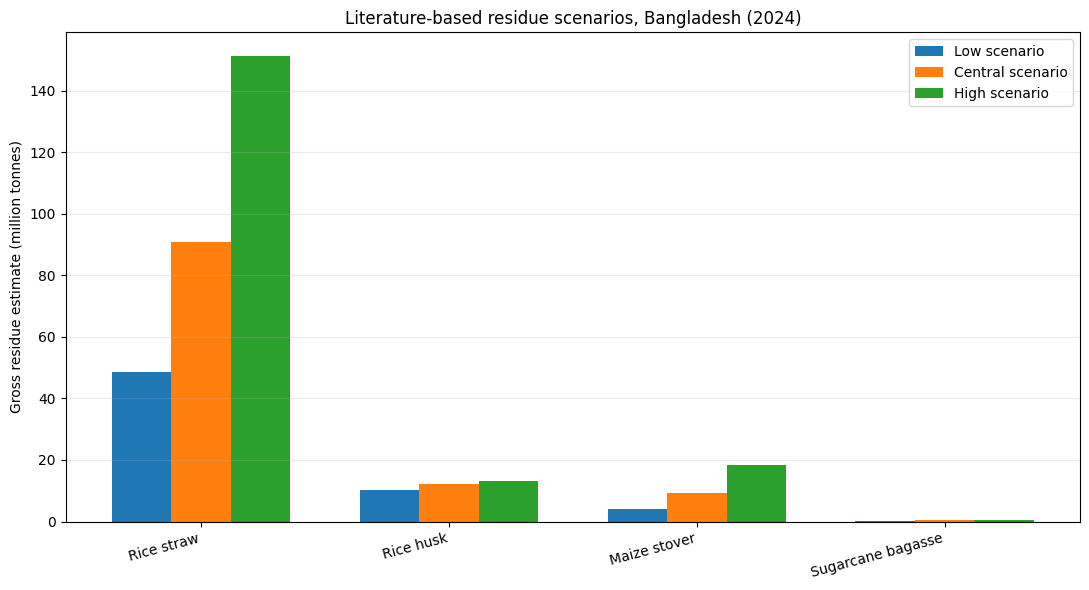

,Residue,Gross_residue_low_tonnes,Gross_residue_central_tonnes,Gross_residue_high_tonnes
28,Rice straw,48456362.0,90855680.0,151426133.0
29,Rice husk,10296977.0,12114091.0,13325500.0
30,Maize stover,4133257.0,9185016.0,18370032.0
31,Sugarcane bagasse,146685.0,440054.0,586739.0


In [ ]:

#  Compare low, central and high estimates for 2024

latest_year = int(biomass["Year"].max())
latest = biomass[biomass["Year"] == latest_year].copy()

labels = latest["Residue"].tolist()
x = np.arange(len(labels))
width = 0.24

plt.figure(figsize=(11, 6))

plt.bar(
    x - width,
    latest["Gross_residue_low_tonnes"] / 1e6,
    width,
    label="Low scenario"
)
plt.bar(
    x,
    latest["Gross_residue_central_tonnes"] / 1e6,
    width,
    label="Central scenario"
)
plt.bar(
    x + width,
    latest["Gross_residue_high_tonnes"] / 1e6,
    width,
    label="High scenario"
)

plt.xticks(x, labels, rotation=15, ha="right")
plt.ylabel("Gross residue estimate (million tonnes)")
plt.title(f"Literature-based residue scenarios, Bangladesh ({latest_year})")
plt.legend()
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

display(
    latest[[
        "Residue",
        "Gross_residue_low_tonnes",
        "Gross_residue_central_tonnes",
        "Gross_residue_high_tonnes"
    ]].round(0)
)


In [ ]:

#  Export the latest-year summary

latest_summary = latest[[
    "Year",
    "Residue",
    "Crop_production_tonnes",
    "RPR_low",
    "RPR_central",
    "RPR_high",
    "Gross_residue_low_tonnes",
    "Gross_residue_central_tonnes",
    "Gross_residue_high_tonnes",
    "Reference",
    "DOI",
    "Caution"
]].copy()

latest_summary.to_csv("biomass_summary_2024.csv", index=False)

files.download("biomass_summary_2024.csv")
files.download("gross_biomass_scenario_estimates.csv")
files.download("literature_RPR_parameters_with_sources.csv")

print("Biomass scenario results exported successfully.")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Biomass scenario results exported successfully.


In [ ]:
#  Calculate recoverable biomass and energy potential (LHV basis)
# Literature-based recovery fractions and moisture contents
recovery_params = pd.DataFrame([
    {
        "Residue": "Rice straw",
        "Recovery_fraction_low": 0.30,
        "Recovery_fraction_central": 0.40,
        "Recovery_fraction_high": 0.50,
        "Moisture_wet_basis": 0.15,
        "LHV_MJ_per_kg_dry": 15.0
    },
    {
        "Residue": "Rice husk",
        "Recovery_fraction_low": 0.80,
        "Recovery_fraction_central": 0.90,
        "Recovery_fraction_high": 0.95,
        "Moisture_wet_basis": 0.10,
        "LHV_MJ_per_kg_dry": 14.5
    },
    {
        "Residue": "Maize stover",
        "Recovery_fraction_low": 0.25,
        "Recovery_fraction_central": 0.35,
        "Recovery_fraction_high": 0.45,
        "Moisture_wet_basis": 0.15,
        "LHV_MJ_per_kg_dry": 17.0
    },
    {
        "Residue": "Sugarcane bagasse",
        "Recovery_fraction_low": 0.70,
        "Recovery_fraction_central": 0.85,
        "Recovery_fraction_high": 0.95,
        "Moisture_wet_basis": 0.50,
        "LHV_MJ_per_kg_dry": 17.5
    }
])

# Merge with latest biomass estimates
latest_energy = latest.merge(recovery_params, on="Residue", how="left")

# Calculate recoverable dry biomass (tonnes)
# Formula: Gross Central * Recovery Central * (1 - Moisture)
latest_energy["Recoverable_dry_mass_tonnes"] = (
    latest_energy["Gross_residue_central_tonnes"]
    * latest_energy["Recovery_fraction_central"]
    * (1 - latest_energy["Moisture_wet_basis"])
)

# Calculate Total Energy Potential in Petajoules (PJ) or GWh
# 1 PJ = 10^9 MJ
latest_energy["Energy_potential_PJ"] = (
    latest_energy["Recoverable_dry_mass_tonnes"]
    * latest_energy["LHV_MJ_per_kg_dry"]
) / 1e3  # Converting MJ to GJ/PJ or TJ

print("Recoverable Biomass & Energy Potential (2024 Central Scenario):")
display(latest_energy[[
    "Residue",
    "Gross_residue_central_tonnes",
    "Recoverable_dry_mass_tonnes",
    "Energy_potential_PJ"
]].round(2))

# Save output
latest_energy.to_csv("recoverable_biomass_energy_potential_2024.csv", index=False)
files.download("recoverable_biomass_energy_potential_2024.csv")
print("\nSaved and downloaded: recoverable_biomass_energy_potential_2024.csv")

Recoverable Biomass & Energy Potential (2024 Central Scenario):


,Residue,Gross_residue_central_tonnes,Recoverable_dry_mass_tonnes,Energy_potential_PJ
0,Rice straw,90855679.57,30890931.06,463363.97
1,Rice husk,12114090.61,9812413.39,142279.99
2,Maize stover,9185016.00,2732542.26,46453.22
3,Sugarcane bagasse,440054.10,187022.99,3272.90


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


Saved and downloaded: recoverable_biomass_energy_potential_2024.csv


In [ ]:
# Estimate potential electricity generation (MW and GWh)
# Assuming an overall system/conversion efficiency (e.g., 20% or 0.20 for thermal-to-electric conversion)
system_efficiency = 0.20

# 1 PJ = 10^9 MJ = 277,778 kWh (or GWh conversion)
# Let's calculate total annual electricity generation in GWh (Gigawatt-hours)
# Formula: Energy_potential_PJ * 10^9 MJ/PJ * efficiency / 3.6*10^6 MJ/kWh / 1000 (to GWh)
# Simplified: Energy_potential_PJ * system_efficiency * (1000 / 3.6) -> Since 1 GWh = 3.6 TJ = 0.0036 PJ, 1 PJ = 277.78 GWh

latest_energy["Electricity_GWh"] = latest_energy["Energy_potential_PJ"] * system_efficiency * 277.78

# Assuming continuous operation throughout the year (8,760 hours/year) to find average capacity in MW
latest_energy["Average_Capacity_MW"] = (latest_energy["Electricity_GWh"] * 1000) / 8760

print("Estimated Electricity Generation Potential (2024 Central Scenario, 20% Efficiency):")
display(latest_energy[[
    "Residue",
    "Recoverable_dry_mass_tonnes",
    "Energy_potential_PJ",
    "Electricity_GWh",
    "Average_Capacity_MW"
]].round(2))

# Save output
latest_energy.to_csv("electricity_generation_potential_2024.csv", index=False)
files.download("electricity_generation_potential_2024.csv")
print("\nSaved and downloaded: electricity_generation_potential_2024.csv")

Estimated Electricity Generation Potential (2024 Central Scenario, 20% Efficiency):


,Residue,Recoverable_dry_mass_tonnes,Energy_potential_PJ,Electricity_GWh,Average_Capacity_MW
0,Rice straw,30890931.06,463363.97,25742648.49,2938658.50
1,Rice husk,9812413.39,142279.99,7904507.36,902341.02
2,Maize stover,2732542.26,46453.22,2580755.00,294606.74
3,Sugarcane bagasse,187022.99,3272.90,181829.36,20756.78


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


Saved and downloaded: electricity_generation_potential_2024.csv


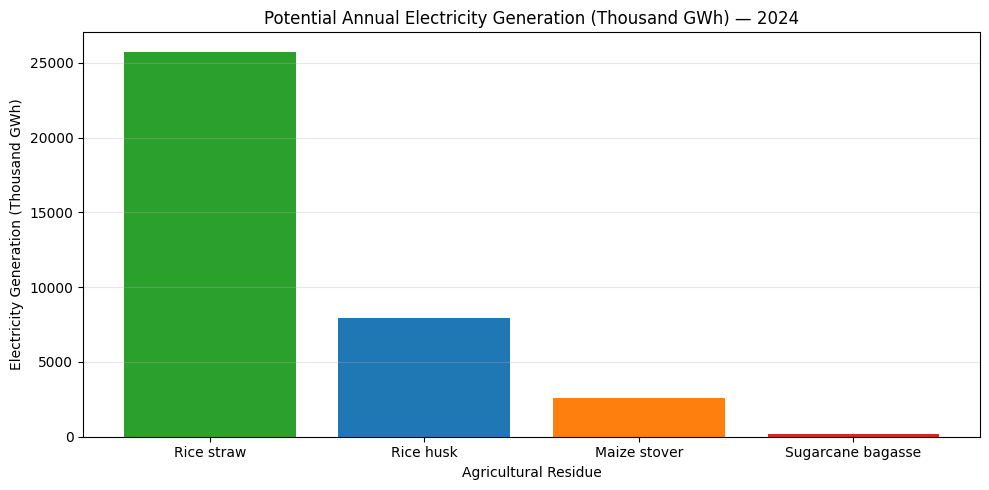

In [ ]:
# Plot electricity generation potential
plt.figure(figsize=(10, 5))
bars = plt.bar(
    latest_energy["Residue"],
    latest_energy["Electricity_GWh"] / 1e3,

    color=["#2ca02c", "#1f77b4", "#ff7f0e", "#d62728"]
)
plt.xlabel("Agricultural Residue")
plt.title("Potential Annual Electricity Generation (Thousand GWh) — 2024")
plt.ylabel("Electricity Generation (Thousand GWh)")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
#  Generate a Master Summary Table for Report
master_summary = latest_energy[[
    "Residue",
    "Crop_production_tonnes",
    "Gross_residue_central_tonnes",
    "Recoverable_dry_mass_tonnes",
    "Energy_potential_PJ",
    "Electricity_GWh",
    "Average_Capacity_MW"
]].copy()

# Rename columns for clear reporting
master_summary.columns = [
    "Agricultural Residue",
    "Crop Production (t)",
    "Gross Residue (t)",
    "Recoverable Dry Mass (t)",
    "Energy Potential (PJ)",
    "Electricity Potential (GWh)",
    "Avg. Capacity (MW)"
]

print("MASTER SUMMARY TABLE (2024) ")
display(master_summary.round(2))

# Save master summary
master_summary.to_csv("master_biomass_energy_summary_2024.csv", index=False)
files.download("master_biomass_energy_summary_2024.csv")
print("\nSaved and downloaded: master_biomass_energy_summary_2024.csv")

MASTER SUMMARY TABLE (2024) 


,Agricultural Residue,Crop Production (t),Gross Residue (t),Recoverable Dry Mass (t),Energy Potential (PJ),Electricity Potential (GWh),Avg. Capacity (MW)
0,Rice straw,60570453.05,90855679.57,30890931.06,463363.97,25742648.49,2938658.50
1,Rice husk,60570453.05,12114090.61,9812413.39,142279.99,7904507.36,902341.02
2,Maize stover,4592508.00,9185016.00,2732542.26,46453.22,2580755.00,294606.74
3,Sugarcane bagasse,2933694.00,440054.10,187022.99,3272.90,181829.36,20756.78


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


Saved and downloaded: master_biomass_energy_summary_2024.csv
